# Лабораторная работа №2

ФИО: Дубинин Глеб Антонович  
Группа: БИВТ-24-СП-3

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №6

Что необходимо сделать:  
**В общих чертах просто провести EDA** (но обычно это не бывает просто)
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. **Найти** в таблице (из исходных данных) название своего датасета
2. **Описать** кратко постановку задачи, что от вас хотят. Какие есть переменные. Целевое событие непрерывно (предсказываем число от -$\infty$ до $\infty$) либо дискретно (предсказываем класс из конечного множества вариантов, например 0 или 1, или какое-то число в диапазоне [0; 10])
3. Построить распределение целевой переменной в виде гистограммы, сделать промежуточные выводы (обратите внимание на однородоность распределения и возможный дисбаланс). Посчитайте количество уникальных значений целевой переменной.
4. Выведите основные статистики по переменным в датасете (для этого есть готовый метод в pandas, он считает count, min, max, mean, 25%, 50% и пр.). Это делается **одним** методом (вы его знаете).
5. Выведите основную информацию по датасету (сколько всего колонок, каких они типов, сколько в них non-null элементов). Это делается **одним** методом (вы его знаете).
6. Посчитайте количество пропусков (NaN, Null, null, None) элементов во всех колонках. Предположите, почему эти пропуски могли возникнуть, и как их можно было бы заменить. 
7. Постройте гистограммы 5 любых признаков (из множества `X`, или как оно изначально у нас называется `data.data`). Если видите какое-то смещение, несимметричность и прочее, опишите это словами в ноутбуке.
8. Постройте графики зависимости 5 любых (на ваш выбор) переменных от целевой переменной (если переменных меньше, чем 5, то сделайте столько, сколько получится). Сделайте вывод, можно ли использовать эти переменные для прогнозирования целевой переменной (иначе говоря, есть ли какая-то взаимосвязь между y-переменной и X-переменной)  
9. _extra_ (необязательно). Посмотрите на зависимость двух переменных одновременно от целевой переменной. То есть по оси OX должна быть переменная $X_{n}$, по оси OY -- переменная $X_{k}$. И у вас будет две кривые (два облака точек) в разрезе целевой переменной. Либо вы можете построить похожее для категориальных признаков, но необходимо будет прочитать про heatmap. 

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

## 0. Пример импорта данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

path_to_dataset = '../../data/apple_quality.csv'
data = pd.read_csv(path_to_dataset)
data.head()

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,0.0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,good
1,1.0,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,good
2,2.0,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,bad
3,3.0,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,good
4,4.0,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,good


## 1. Название датасета

Apple Quality (Kaggle, `nelgiriyewithana/apple-quality`), файл `apple_quality.csv`.

## 2. Описание постановки задачи

Датасет с характеристиками 4000 яблок. По характеристикам нужно понять, хорошее яблоко или нет.

Переменные:
- `A_id` - номер яблока, для модели не нужен
- `Size`, `Weight`, `Sweetness`, `Crunchiness`, `Juiciness`, `Ripeness`, `Acidity` - размер, вес, сладость, хруст, сочность, спелость, кислотность (все числовые, значения уже отмасштабированы и лежат около нуля)
- `Quality` - целевая переменная, `good` или `bad`

Целевая переменная дискретная (два класса), значит это бинарная классификация.

In [2]:
data.tail(3)

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
3998,3998.0,-4.008004,-1.779337,2.366397,-0.200329,2.161435,0.214488,-2.229719806,good
3999,3999.0,0.278540,-1.715505,0.121217,-1.154075,1.266677,-0.776571,1.599796456,good
4000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Created_by_Nidula_Elgiriyewithana,NaN


В конце файла лишняя строка: вместо яблока там подпись автора датасета (`Created_by_...`). Из-за неё `Acidity` прочитался как текст. Убираю эту строку и привожу типы.

In [3]:
data = data.dropna(subset=['Quality'])
data['Acidity'] = data['Acidity'].astype(float)
data['A_id'] = data['A_id'].astype(int)
data.shape

(4000, 9)

## 3. Распределение целевой переменной

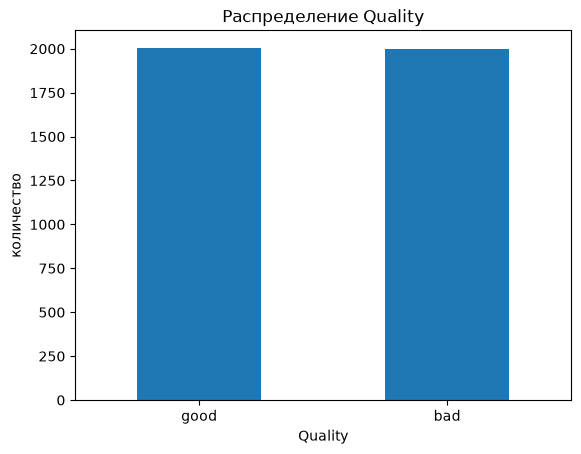

Quality
good    2004
bad     1996
Name: count, dtype: int64
уникальных значений: 2


In [4]:
data['Quality'].value_counts().plot(kind='bar')
plt.xticks(rotation=0)
plt.title('Распределение Quality')
plt.ylabel('количество')
plt.show()

print(data['Quality'].value_counts())
print('уникальных значений:', data['Quality'].nunique())

Классы почти поровну: `good` - 2004, `bad` - 1996, всего 2 уникальных значения. Дисбаланса нет.

## 4. Основные статистики

In [5]:
data.describe()

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,1999.500000,-0.503015,-0.989547,-0.470479,0.985478,0.512118,0.498277,0.076877
std,1154.844867,1.928059,1.602507,1.943441,1.402757,1.930286,1.874427,2.110270
min,0.000000,-7.151703,-7.149848,-6.894485,-6.055058,-5.961897,-5.864599,-7.010538
25%,999.750000,-1.816765,-2.011770,-1.738425,0.062764,-0.801286,-0.771677,-1.377424
50%,1999.500000,-0.513703,-0.984736,-0.504758,0.998249,0.534219,0.503445,0.022609
75%,2999.250000,0.805526,0.030976,0.801922,1.894234,1.835976,1.766212,1.510493
max,3999.000000,6.406367,5.790714,6.374916,7.619852,7.364403,7.237837,7.404736


Значения признаков лежат примерно от -7 до +7.6, средние небольшие (от -1 у `Weight` до +1 у `Crunchiness`), стандартное отклонение от 1.4 до 2.1. Похоже, данные уже отмасштабированы, поэтому единицы измерения условные (у веса даже бывают отрицательные значения). `A_id` - просто номер от 0 до 3999.

## 5. Информация о датасете

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   A_id         4000 non-null   int64  
 1   Size         4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Sweetness    4000 non-null   float64
 4   Crunchiness  4000 non-null   float64
 5   Juiciness    4000 non-null   float64
 6   Ripeness     4000 non-null   float64
 7   Acidity      4000 non-null   float64
 8   Quality      4000 non-null   str    
dtypes: float64(7), int64(1), str(1)
memory usage: 281.4 KB


4000 строк и 9 колонок: `A_id` - int, семь признаков - float, `Quality` - текст. Везде 4000 non-null, то есть пропусков нет.

## 6. Пропуски

In [7]:
# исходный файл до удаления лишней строки
print(pd.read_csv(path_to_dataset).isna().sum())

# после
print(data.isna().sum())

A_id           1
Size           1
Weight         1
Sweetness      1
Crunchiness    1
Juiciness      1
Ripeness       1
Acidity        0
Quality        1
dtype: int64
A_id           0
Size           0
Weight         0
Sweetness      0
Crunchiness    0
Juiciness      0
Ripeness       0
Acidity        0
Quality        0
dtype: int64


В исходном файле по одному пропуску в каждой колонке, кроме `Acidity` (там вместо NaN текст) - это та самая лишняя строка с подписью автора. Настоящих пропусков в данных нет, после удаления строки их 0. Скорее всего, строка появилась при выгрузке датасета: в конец дописали копирайт.

Если бы пропуски были в самих признаках, числовые можно было бы заполнить медианой или средним (считать по train), а строки с пропущенной целевой - просто выкинуть.

## 7. Гистограммы признаков

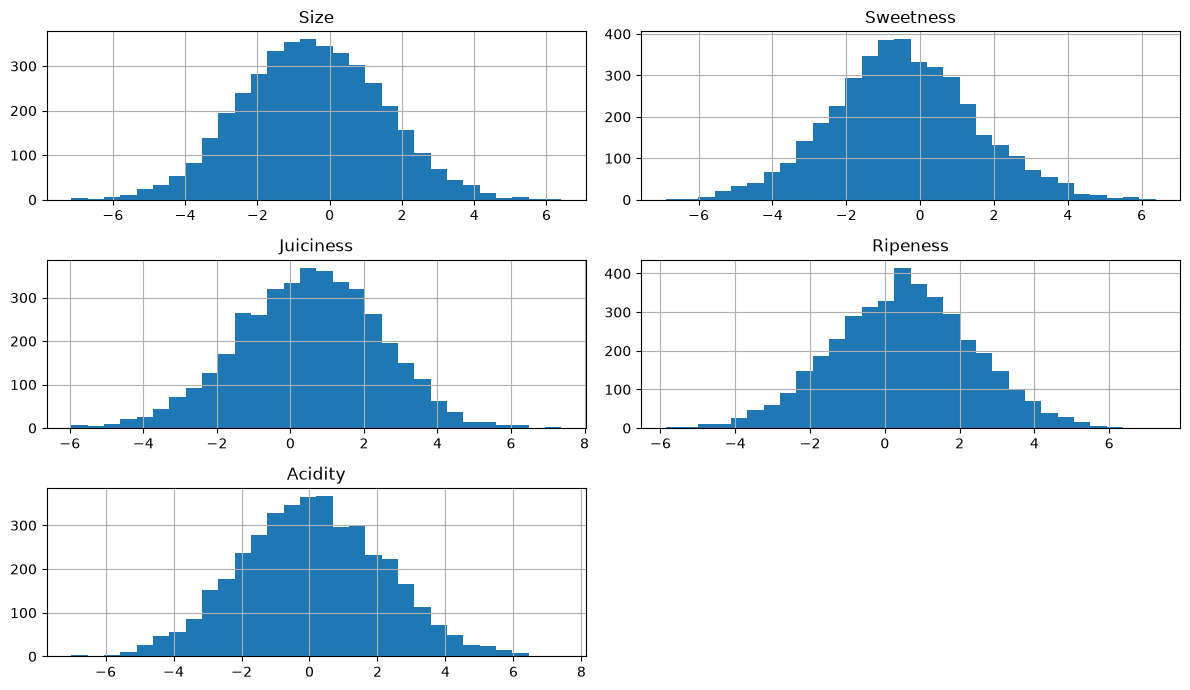

Size        -0.002437
Sweetness    0.083850
Juiciness   -0.113421
Ripeness    -0.008764
Acidity      0.055783
dtype: float64


In [8]:
cols = ['Size', 'Sweetness', 'Juiciness', 'Ripeness', 'Acidity']
data[cols].hist(bins=30, figsize=(12, 7))
plt.tight_layout()
plt.show()

print(data[cols].skew())

Все пять гистограмм колоколообразные и почти симметричные, асимметрия около нуля (по модулю не больше 0.12). Явного смещения нет, выбросов почти нет: хвосты тянутся до +-6-7, но точек там мало. На вид похоже на нормальное распределение.

## 8. Признаки и целевая переменная

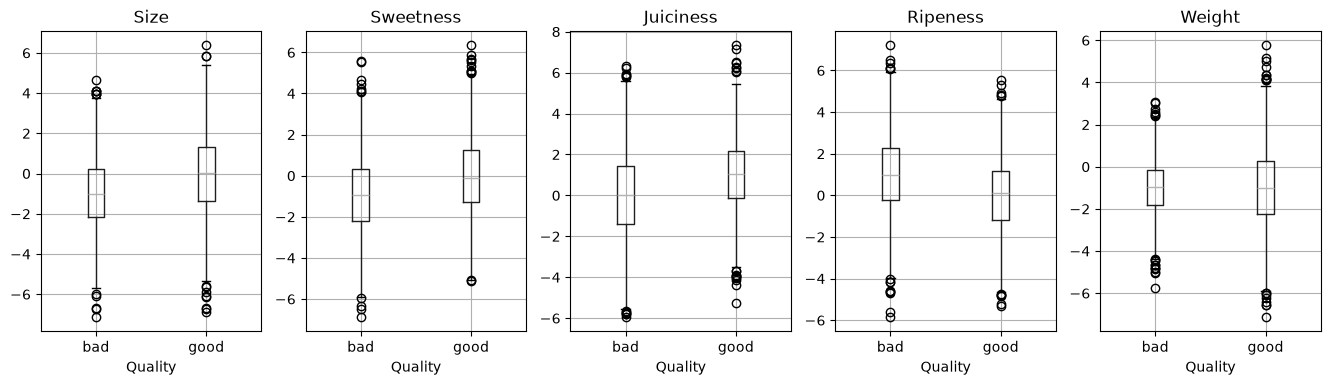

             Size  Sweetness  Juiciness  Ripeness    Weight
Quality                                                    
bad     -1.019633  -0.921758   0.005241  0.965054 -0.975703
good     0.025554  -0.116781   1.024190  0.095571 -0.994428
Size         0.244007
Sweetness    0.250998
Juiciness    0.260223
Ripeness    -0.264315
Weight       0.001421
dtype: float64


In [9]:
cols = ['Size', 'Sweetness', 'Juiciness', 'Ripeness', 'Weight']

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, cols):
    data.boxplot(column=col, by='Quality', ax=ax)
    ax.set_title(col)
plt.suptitle('')
plt.show()

print(data.groupby('Quality')[cols].median())
print(data[cols].corrwith((data['Quality'] == 'good').astype(int)))

У `good` яблок размер, сладость и сочность выше (медианы: `Size` -1.02 -> 0.03, `Sweetness` -0.92 -> -0.12, `Juiciness` 0.01 -> 1.02), а спелость ниже (0.97 -> 0.10). Корреляция с целью около +-0.25. У `Weight` медианы почти одинаковые у обоих классов (-0.98 и -0.99, корреляция 0.00), по нему класс не предскажешь.

Значит, `Size`, `Sweetness`, `Juiciness` и `Ripeness` для прогноза пригодны, но связь слабая: боксплоты сильно перекрываются, по одному признаку класс уверенно не определить, лучше брать их вместе.